In [82]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [83]:
generation = pd.read_csv(
    '../data/raw/generation.csv', 
    sep=';', decimal=',', thousands='.', 
    na_values=['-', 'n.a.', '']
)
prices = pd.read_csv(
    '../data/raw/prices.csv', 
    sep=';', decimal=',', thousands='.', 
    na_values=['-', 'n.a.', '']
)

In [84]:
generation.info()

<class 'pandas.DataFrame'>
RangeIndex: 26304 entries, 0 to 26303
Data columns (total 14 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   Start date                                         26304 non-null  str    
 1   End date                                           26304 non-null  str    
 2   Biomass [MWh] Calculated resolutions               26304 non-null  str    
 3   Hydropower [MWh] Calculated resolutions            26285 non-null  str    
 4   Wind offshore [MWh] Calculated resolutions         26304 non-null  str    
 5   Wind onshore [MWh] Calculated resolutions          26304 non-null  str    
 6   Photovoltaics [MWh] Calculated resolutions         26304 non-null  str    
 7   Other renewable [MWh] Calculated resolutions       26304 non-null  int64  
 8   Nuclear [MWh] Calculated resolutions               5125 non-null   float64
 9   Lignite [MWh] Cal

In [85]:
def to_number(num):
    if not isinstance(num, str) or pd.isna(num):
        return num

    # 2. Safely perform string replacement
    clean_val = num.replace(".", "").replace(",", ".")

    try:
        return float(clean_val)
    except ValueError:
        return np.nan  # Returns NaN if it's a word or unparseable text

In [86]:
col1=['Biomass [MWh] Calculated resolutions','Hydropower [MWh] Calculated resolutions','Wind offshore [MWh] Calculated resolutions','Wind onshore [MWh] Calculated resolutions','Photovoltaics [MWh] Calculated resolutions','Other renewable [MWh] Calculated resolutions','Nuclear [MWh] Calculated resolutions','Lignite [MWh] Calculated resolutions','Hard coal [MWh] Calculated resolutions','Fossil gas [MWh] Calculated resolutions','Hydro pumped storage [MWh] Calculated resolutions','Other conventional [MWh] Calculated resolutions']
col2=['Germany/Luxembourg [€/MWh] Calculated resolutions','∅ DE/LU neighbours [€/MWh] Calculated resolutions','Belgium [€/MWh] Calculated resolutions','Denmark 1 [€/MWh] Calculated resolutions','Denmark 2 [€/MWh] Calculated resolutions','France [€/MWh] Calculated resolutions','Netherlands [€/MWh] Calculated resolutions','Norway 2 [€/MWh] Calculated resolutions','Austria [€/MWh] Calculated resolutions','Poland [€/MWh] Calculated resolutions','Sweden 4 [€/MWh] Calculated resolutions','Switzerland [€/MWh] Calculated resolutions','Czech Republic [€/MWh] Calculated resolutions','DE/AT/LU [€/MWh] Calculated resolutions','Northern Italy [€/MWh] Calculated resolutions','Slovenia [€/MWh] Calculated resolutions','Hungary [€/MWh] Calculated resolutions']

generation[col1] = generation[col1].apply(to_number)
prices[col2]= prices[col2].apply(to_number)

In [87]:
generation.info()

<class 'pandas.DataFrame'>
RangeIndex: 26304 entries, 0 to 26303
Data columns (total 14 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   Start date                                         26304 non-null  str    
 1   End date                                           26304 non-null  str    
 2   Biomass [MWh] Calculated resolutions               26304 non-null  str    
 3   Hydropower [MWh] Calculated resolutions            26285 non-null  str    
 4   Wind offshore [MWh] Calculated resolutions         26304 non-null  str    
 5   Wind onshore [MWh] Calculated resolutions          26304 non-null  str    
 6   Photovoltaics [MWh] Calculated resolutions         26304 non-null  str    
 7   Other renewable [MWh] Calculated resolutions       26304 non-null  int64  
 8   Nuclear [MWh] Calculated resolutions               5125 non-null   float64
 9   Lignite [MWh] Cal

In [ ]:
prices.head(2)

,Start date,End date,Germany/Luxembourg [€/MWh] Calculated resolutions,∅ DE/LU neighbours [€/MWh] Calculated resolutions,Belgium [€/MWh] Calculated resolutions,Denmark 1 [€/MWh] Calculated resolutions,Denmark 2 [€/MWh] Calculated resolutions,France [€/MWh] Calculated resolutions,Netherlands [€/MWh] Calculated resolutions,Norway 2 [€/MWh] Calculated resolutions,Austria [€/MWh] Calculated resolutions,Poland [€/MWh] Calculated resolutions,Sweden 4 [€/MWh] Calculated resolutions,Switzerland [€/MWh] Calculated resolutions,Czech Republic [€/MWh] Calculated resolutions,DE/AT/LU [€/MWh] Calculated resolutions,Northern Italy [€/MWh] Calculated resolutions,Slovenia [€/MWh] Calculated resolutions,Hungary [€/MWh] Calculated resolutions
0,"Jul 1, 2023 12:00 AM","Jul 1, 2023 1:00 AM",10974,9829,9441,10974,10974,8568,10156,9727,11214,13485,2237,9786,11559,NaN,11341,113.41,11916
1,"Jul 1, 2023 1:00 AM","Jul 1, 2023 2:00 AM",10891,9158,8117,9950,9950,6475,9950,9202,11095,13253,2049,9253,11448,NaN,11123,111.23,11739
2,"Jul 1, 2023 2:00 AM","Jul 1, 2023 3:00 AM",10431,8296,6809,8548,8548,6143,8328,8300,11182,11564,2017,8954,10866,NaN,11076,110.76,11147
3,"Jul 1, 2023 3:00 AM","Jul 1, 2023 4:00 AM",9914,7445,4370,7996,7996,3387,6689,7764,11118,11907,1996,8030,10644,NaN,11188,109.75,11119
4,"Jul 1, 2023 4:00 AM","Jul 1, 2023 5:00 AM",9811,6648,3109,6730,6730,1825,6003,6535,11013,11081,1977,7734,10391,NaN,11123,107.42,10751


In [6]:
generation['Start date']=pd.to_datetime(generation['Start date'])
generation['End date']=pd.to_datetime(generation['End date'])
prices['Start date']=pd.to_datetime(prices['Start date'])
prices['End date']=pd.to_datetime(prices['End date'])

/var/folders/8z/4zb5dgp51p1bzhw0gtptq2r00000gn/T/ipykernel_97770/640262613.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  generation['Start date']=pd.to_datetime(generation['Start date'])
/var/folders/8z/4zb5dgp51p1bzhw0gtptq2r00000gn/T/ipykernel_97770/640262613.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  prices['Start date']=pd.to_datetime(prices['Start date'])


In [7]:
df=pd.DataFrame(index=prices.index)
df['price_eur_mwh'] = prices['Germany/Luxembourg [€/MWh] Calculated resolutions']
df['wind_onshore_mwh'] = generation['Wind onshore [MWh] Calculated resolutions']
df['wind_offshore_mwh'] = generation['Wind offshore [MWh] Calculated resolutions']
df['solar_mwh'] = generation['Photovoltaics [MWh] Calculated resolutions']

df['variable_renewables_mwh'] = df['wind_onshore_mwh'] + df['wind_offshore_mwh'] + df['solar_mwh']

df=df.dropna(subset=['price_eur_mwh'], axis=0)

df.head(5)

,price_eur_mwh,wind_onshore_mwh,wind_offshore_mwh,solar_mwh,variable_renewables_mwh
0,10974,"5,268.00","3,708.00",3.25,"5,268.003,708.003.25"
1,10891,"6,788.75","4,170.00",2.00,"6,788.754,170.002.00"
2,10431,"8,573.75","4,818.00",2.25,"8,573.754,818.002.25"
3,9914,"10,105.50","4,860.75",2.00,"10,105.504,860.752.00"
4,9811,"11,578.25","5,210.00",5.00,"11,578.255,210.005.00"


Total hours with negative prices: 1535 out of 26304 (5.8%)


Text(0.5, 1.0, 'Distribution of Day-Ahead Electricity Prices in Germany')

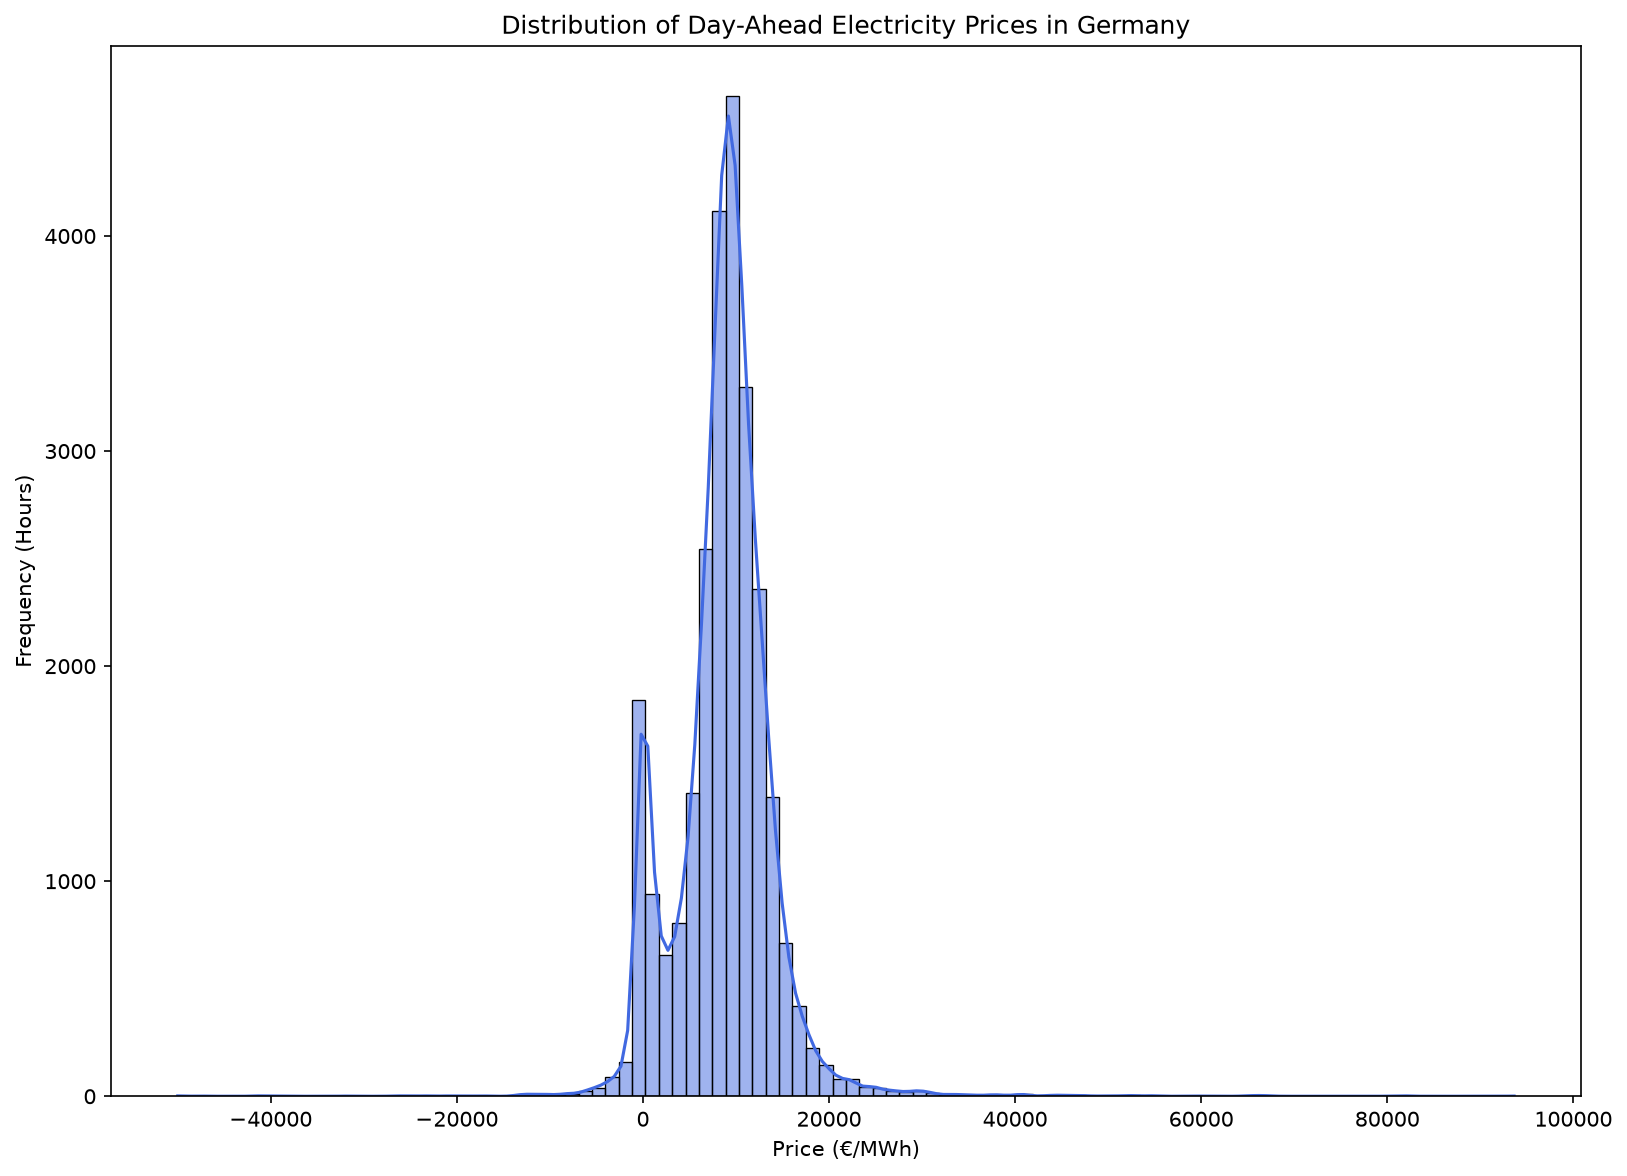

In [8]:
neg_hours = (df["price_eur_mwh"] < 0).sum()
total_hours = len(df)
print(f"Total hours with negative prices: {neg_hours} out of {total_hours} ({neg_hours/total_hours:.1%})")

fig=plt.figure(dpi=150,figsize=(14,10))
axes=fig.add_axes([0,0,0.7,0.7])
sns.histplot(data=df,x='price_eur_mwh',bins=100,kde=True,color='royalblue')
axes.set_xlabel('Price (€/MWh)')
axes.set_ylabel('Frequency (Hours)')
plt.title('Distribution of Day-Ahead Electricity Prices in Germany')

In [9]:
df.head()

,price_eur_mwh,wind_onshore_mwh,wind_offshore_mwh,solar_mwh,variable_renewables_mwh
0,10974,"5,268.00","3,708.00",3.25,"5,268.003,708.003.25"
1,10891,"6,788.75","4,170.00",2.00,"6,788.754,170.002.00"
2,10431,"8,573.75","4,818.00",2.25,"8,573.754,818.002.25"
3,9914,"10,105.50","4,860.75",2.00,"10,105.504,860.752.00"
4,9811,"11,578.25","5,210.00",5.00,"11,578.255,210.005.00"


In [10]:
def to_number(num):
    if not isinstance(num, str) or pd.isna(num):
        return num

    # 2. Safely perform string replacement
    clean_val = num.replace(".", "").replace(",", ".")

    try:
        return float(clean_val)
    except ValueError:
        return np.nan  # Returns NaN if it's a word or unparseable text


In [11]:
vectorized_cleaner = np.vectorize(to_number, otypes=[float])
df = pd.DataFrame(vectorized_cleaner(df), columns=df.columns)

In [12]:
df['variable_renewables_mwh'] = df['wind_onshore_mwh'] + df['wind_offshore_mwh'] + df['solar_mwh']

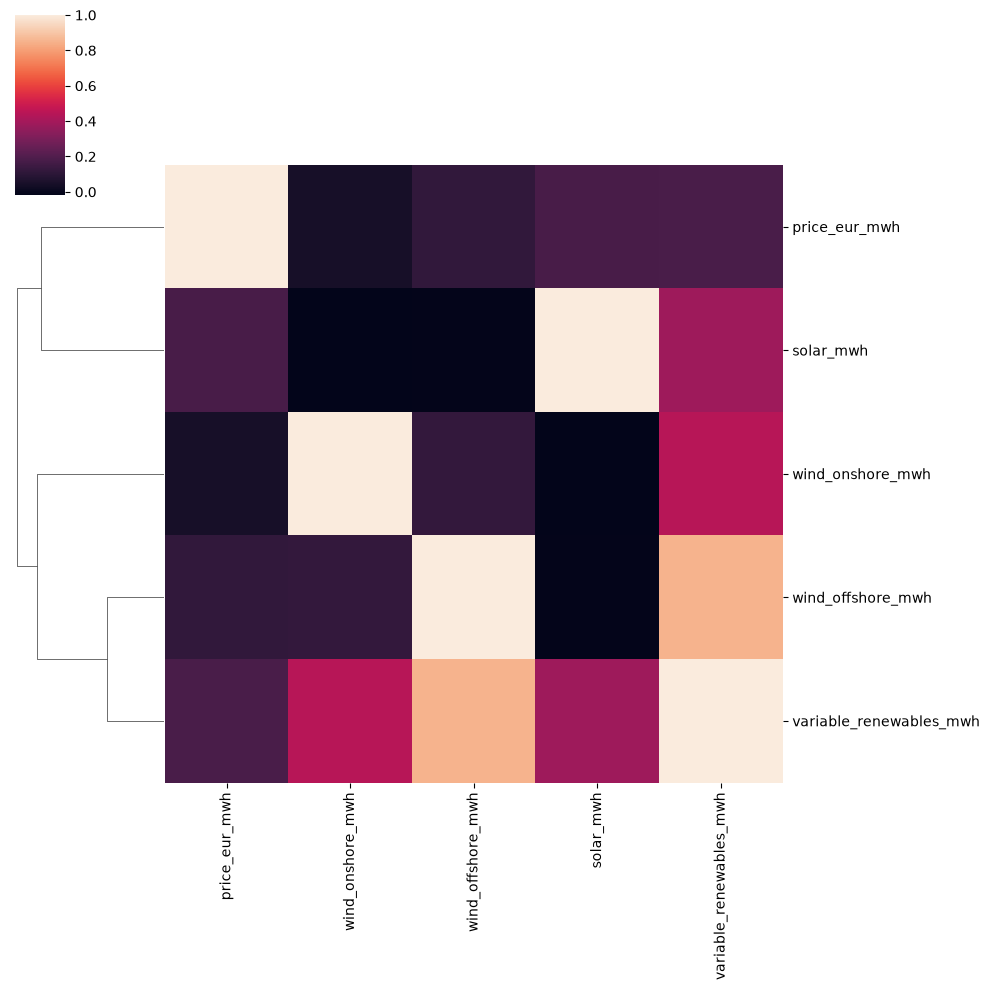

In [13]:

sns.clustermap(df.corr(),col_cluster=False)

<Axes: xlabel='variable_renewables_mwh', ylabel='price_eur_mwh'>

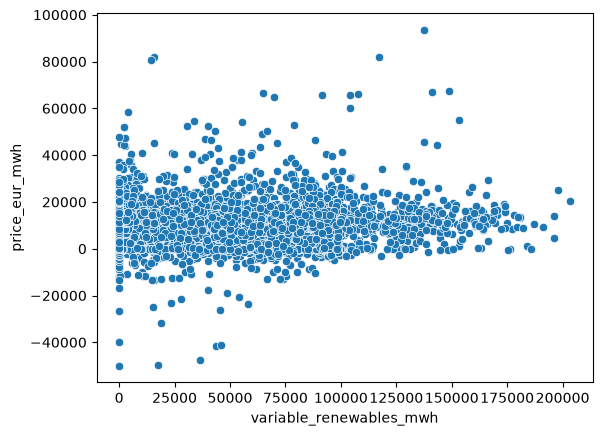

In [14]:
sns.scatterplot(data=df,x='variable_renewables_mwh',y='price_eur_mwh')